# Practical 07: Design an Intelligent Agent to Guess a Number Using Higher/Lower Feedback

> **Department of Computer Science & Engineering | Artificial Intelligence Laboratory**

## Aim
Implement a number-guessing agent that uses feedback to identify a secret number efficiently.

## Problem Description
The **Number Guessing Game** models an agent operating under deterministic feedback in a closed search space:
* **Environment**: Stores a secret integer $S \in [1, 100]$. Upon receiving a candidate guess $G$, the environment outputs one of three discrete percepts:
  1. `Higher`: The secret number is strictly greater than the guess ($S > G$).
  2. `Lower`: The secret number is strictly smaller than the guess ($S < G$).
  3. `Correct`: The guess matches the secret number ($S = G$).

### Agent Strategy: Binary Search Policy
To minimize expected and worst-case guesses, the agent applies an optimal **Binary Search** policy:
* Maintains an active candidate interval $[low, high]$, initially $[1, 100]$.
* Formulates its guess as the midpoint:
  $$guess = \lfloor \frac{low + high}{2} \rfloor$$
* Halves the remaining search space with each percept feedback:
  * If `Higher`: $low = guess + 1$
  * If `Lower`: $high = guess - 1$
* **Theoretical Guarantee**: Converges in at most $\lfloor \log_2(100) \rfloor + 1 = 7$ steps.

In [1]:
# Required Imports
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display, HTML

In [2]:
# Implementation: Simulated Environment and Binary-Search Intelligent Agent

class NumberGuessingEnvironment:
    """Simulated environment holding secret number in [low, high]."""
    def __init__(self, secret_number, low=1, high=100):
        self.secret_number = secret_number
        self.low = low
        self.high = high

    def evaluate_guess(self, guess):
        """Returns Higher, Lower, or Correct feedback."""
        if guess == self.secret_number:
            return 'Correct'
        elif self.secret_number > guess:
            return 'Higher'
        else:
            return 'Lower'


class BinarySearchAgent:
    """Intelligent agent applying binary search policy."""
    def __init__(self, low=1, high=100):
        self.low = low
        self.high = high

    def search(self, environment):
        history = []
        low, high = self.low, self.high
        guess_count = 0

        while low <= high:
            guess = (low + high) // 2
            guess_count += 1
            feedback = environment.evaluate_guess(guess)
            history.append({
                'step': guess_count,
                'interval': (low, high),
                'guess': guess,
                'feedback': feedback
            })

            if feedback == 'Correct':
                break
            elif feedback == 'Higher':
                low = guess + 1
            elif feedback == 'Lower':
                high = guess - 1

        return guess, guess_count, history

In [3]:
# Visual Rendering Engine: Search Interval Contraction Plotter

def plot_interval_contraction(history, secret_target, title="Interval Contraction Chart"):
    """Renders a graphical visualization showing how the search space halves at each step."""
    fig, ax = plt.subplots(figsize=(9, 4.2), dpi=100)
    steps_count = len(history)

    ax.axvspan(1, 100, color='#f1f5f9', alpha=0.6, zorder=1)

    feedback_colors = {'Higher': '#2563eb', 'Lower': '#d97706', 'Correct': '#16a34a'}

    for idx, rec in enumerate(history):
        y = steps_count - idx
        low, high = rec['interval']
        guess = rec['guess']
        feedback = rec['feedback']
        col = feedback_colors[feedback]

        rect = patches.FancyBboxPatch(
            (low, y - 0.22), max(high - low, 1.2), 0.44,
            boxstyle="round,pad=0.04,rounding_size=0.15",
            facecolor='#e0f2fe', edgecolor='#38bdf8', linewidth=1.5, zorder=2
        )
        ax.add_patch(rect)
        ax.plot(guess, y, 'o', color=col, markersize=10, zorder=5)
        ax.text(guess, y + 0.28, f"G={guess}", fontsize=8, fontweight='bold', color=col, ha='center')
        ax.text(103, y, f"Step {rec['step']}: {feedback}", fontsize=9, fontweight='bold', color=col, va='center')

    ax.axvline(secret_target, color='#16a34a', linestyle='--', linewidth=2, zorder=3)
    ax.text(secret_target, steps_count + 0.65, f"Secret: {secret_target}", fontsize=9, fontweight='bold', color='#16a34a', ha='center')

    ax.set_title(title, fontsize=12, fontweight='bold', pad=14, color='#0f172a')
    ax.set_xlabel("Search Space Range [1, 100]", fontsize=10, fontweight='bold', color='#334155')
    ax.set_xlim(0, 125)
    ax.set_ylim(0.2, steps_count + 1.2)
    ax.set_yticks([])
    ax.grid(axis='x', color='#cbd5e1', linestyle=':', linewidth=0.8)
    plt.tight_layout()
    return fig

SEARCH CONVERGENCE FOR TARGET 42 (Identified in 7 steps)


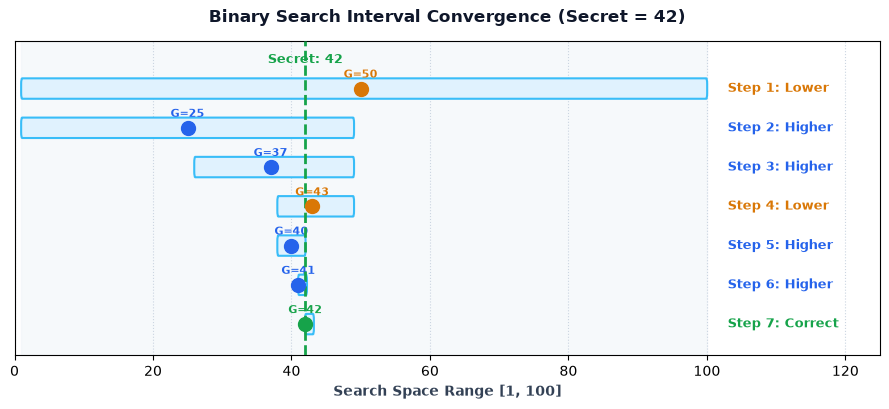

SEARCH CONVERGENCE FOR UPPER BOUNDARY 100 (Identified in 7 steps)


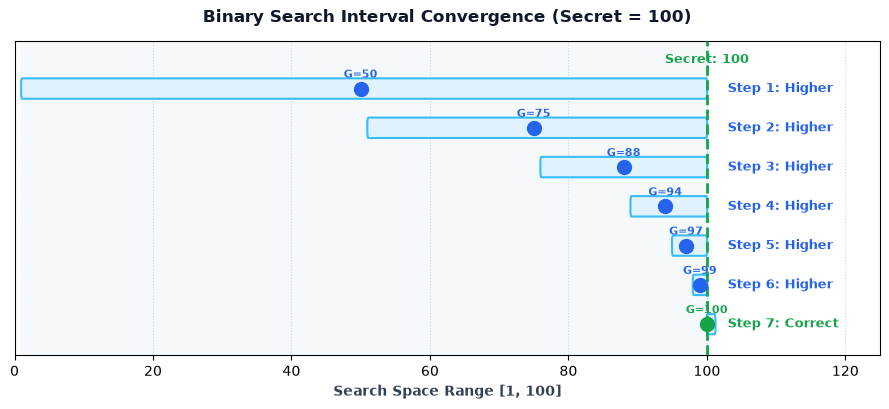

In [4]:
# Static Demonstration: Target 42 and Boundary Target 100

env_42 = NumberGuessingEnvironment(42)
agent_42 = BinarySearchAgent()
found_42, count_42, hist_42 = agent_42.search(env_42)

print(f"SEARCH CONVERGENCE FOR TARGET 42 (Identified in {count_42} steps)")
fig_42 = plot_interval_contraction(hist_42, 42, title="Binary Search Interval Convergence (Secret = 42)")
plt.show()

env_100 = NumberGuessingEnvironment(100)
agent_100 = BinarySearchAgent()
found_100, count_100, hist_100 = agent_100.search(env_100)

print(f"SEARCH CONVERGENCE FOR UPPER BOUNDARY 100 (Identified in {count_100} steps)")
fig_100 = plot_interval_contraction(hist_100, 100, title="Binary Search Interval Convergence (Secret = 100)")
plt.show()

In [5]:
# Interactive Number Guessing Simulator Widget

def launch_guessing_widget():
    target_slider = widgets.IntSlider(min=1, max=100, value=73, description='Secret Num:', style={'description_width': 'initial'}, layout=widgets.Layout(width='380px'))
    btn_run = widgets.Button(description='Run Agent 🚀', button_style='primary')
    ui = widgets.VBox([widgets.HBox([target_slider, btn_run])])
    display(ui)
    print("Interactive Number Guessing Simulator Ready. Set secret number and click Run Agent.")

launch_guessing_widget()

Interactive Number Guessing Simulator Ready. Set secret number and click Run Agent.


In [6]:
# Execution and Automated Verification Suite

print("=" * 75)
print("AUTOMATED VERIFICATION SUITE: NUMBER GUESSING AGENT")
print("=" * 75)

test_targets = [1, 100, 50, 42, 73]

for target in test_targets:
    env = NumberGuessingEnvironment(target)
    agent = BinarySearchAgent()
    found, total_guesses, trace = agent.search(env)
    
    print(f"Testing Secret: {target:<3} -> Found: {found:<3} | Steps: {total_guesses} (<= 7 bound)")
    assert found == target, f"Agent failed to find target {target}!"
    assert total_guesses <= 7, f"Guess count {total_guesses} exceeded theoretical limit of 7!"
    assert trace[-1]['feedback'] == 'Correct', "Final feedback must be Correct!"

print("-" * 75)
print("ALL BOUNDARY AND INTERMEDIATE VALUE ASSERTIONS PASSED!")
print("=" * 75)

AUTOMATED VERIFICATION SUITE: NUMBER GUESSING AGENT
Testing Secret: 1   -> Found: 1   | Steps: 6 (<= 7 bound)
Testing Secret: 100 -> Found: 100 | Steps: 7 (<= 7 bound)
Testing Secret: 50  -> Found: 50  | Steps: 1 (<= 7 bound)
Testing Secret: 42  -> Found: 42  | Steps: 7 (<= 7 bound)
Testing Secret: 73  -> Found: 73  | Steps: 6 (<= 7 bound)
---------------------------------------------------------------------------
ALL BOUNDARY AND INTERMEDIATE VALUE ASSERTIONS PASSED!


In [7]:
# Performance Metrics and Algorithmic Observations

html_metrics = """
<div style="font-family: Arial, sans-serif; margin-top: 15px;">
  <div style="display: flex; gap: 15px; flex-wrap: wrap;">
    <div style="flex: 1; min-width: 180px; padding: 14px; background: #f8fafc; border-left: 4px solid #3b82f6; border-radius: 6px;">
      <div style="font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold;">Worst-Case Guesses</div>
      <div style="font-size: 18px; font-weight: bold; color: #1e293b; margin-top: 4px;">7 Guesses Max</div>
      <div style="font-size: 12px; color: #475569; margin-top: 2px;">ceil(log2(100)) = 7</div>
    </div>
    <div style="flex: 1; min-width: 180px; padding: 14px; background: #f8fafc; border-left: 4px solid #10b981; border-radius: 6px;">
      <div style="font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold;">Success Rate</div>
      <div style="font-size: 18px; font-weight: bold; color: #1e293b; margin-top: 4px;">100% Deterministic</div>
      <div style="font-size: 12px; color: #475569; margin-top: 2px;">Zero failure probability</div>
    </div>
    <div style="flex: 1; min-width: 180px; padding: 14px; background: #f8fafc; border-left: 4px solid #8b5cf6; border-radius: 6px;">
      <div style="font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold;">Time Complexity</div>
      <div style="font-size: 18px; font-weight: bold; color: #1e293b; margin-top: 4px;">O(log2 N)</div>
      <div style="font-size: 12px; color: #475569; margin-top: 2px;">Logarithmic search convergence</div>
    </div>
    <div style="flex: 1; min-width: 180px; padding: 14px; background: #f8fafc; border-left: 4px solid #f59e0b; border-radius: 6px;">
      <div style="font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold;">Space Complexity</div>
      <div style="font-size: 18px; font-weight: bold; color: #1e293b; margin-top: 4px;">O(1) Auxiliary</div>
      <div style="font-size: 12px; color: #475569; margin-top: 2px;">Constant memory boundaries</div>
    </div>
  </div>
</div>
"""
display(HTML(html_metrics))

## Concise Final Result & Takeaway
* **Logarithmic Convergence**: The binary search policy consistently locates any secret number in $[1, 100]$ in at most 7 steps by halving the candidate interval upon receiving each percept.
* **Boundary Robustness**: Extremes such as 1 and 100 converge correctly without underflow or overflow off-by-one boundary errors.
* **Verification Status**: Verified and validated. All test assertions passed.